# ¿Cuál es la mejor tarifa?

Trabajas como analista para el operador de telecomunicaciones Megaline. La empresa ofrece a sus clientes dos tarifas de prepago, Surf y Ultimate. El departamento comercial quiere saber cuál de las tarifas genera más ingresos para poder ajustar el presupuesto de publicidad.

Vas a realizar un análisis preliminar de las tarifas basado en una selección de clientes relativamente pequeña. Tendrás los datos de 500 clientes de Megaline: quiénes son los clientes, de dónde son, qué tarifa usan, así como la cantidad de llamadas que hicieron y los mensajes de texto que enviaron en 2018. Tu trabajo es analizar el comportamiento de los clientes y determinar qué tarifa de prepago genera más ingresos.

El próposito en este proyecto es el siguiente:

1. Realizar limpieza y organización de los datos.
2. Iniciar el análisis de los datos de acuerdo con las preguntas que se formulen. ayudarme con gráficos y nuevas tablas que se requieran.
3. Realizar el análisis estadístico que se requiera, de acuerdo a las hipótesis que surjan y validar dichas hipótesis.

## Inicialización

In [1]:
# Cargar todas las librerías
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from scipy import stats as st


## Cargar datos

In [2]:
# Carga los archivos de datos en diferentes DataFrames
df_users = pd.read_csv('/datasets/megaline_users.csv')
df_calls = pd.read_csv('/datasets/megaline_calls.csv')
df_messages = pd.read_csv('/datasets/megaline_messages.csv')
df_internet = pd.read_csv('/datasets/megaline_internet.csv')
df_plans = pd.read_csv('/datasets/megaline_plans.csv')


## Preparar los datos

1. Limpieza de todos los DataFrames

## Tarifas

In [3]:
# Imprime la información general/resumida sobre el DataFrame de las tarifas
print(df_plans.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 256.0+ bytes
None


In [4]:
# Imprime una muestra de los datos para las tarifas
print(df_plans.sample(2))


   messages_included  mb_per_month_included  minutes_included  \
0                 50                  15360               500   
1               1000                  30720              3000   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute plan_name  
0               20          10             0.03            0.03      surf  
1               70           7             0.01            0.01  ultimate  


Realmente la tabla no presenta mayores desviaciones, es una tabla informativa sobre los beneficios de cada plan. sin embargo, encuentro 2 oportunidades de mejora para esta tabla:
1. Ajustar el internet ofrecido de Mb y Gb.
2. Dejar como indice del dataframe los nombres de los planes.

## Corregir datos

In [5]:
#cambio de unidades de internet ofrecidas:
df_plans['gb_per_month_included']=df_plans['mb_per_month_included']/1024

#Eliminar columna de mb_per_month_included
df_plans = df_plans.drop('mb_per_month_included', axis = 1)

## Enriquecer los datos

In [6]:
#Fijar los nombres de los planes como indice del datagrame
df_plans = df_plans.set_index('plan_name')

#Reorganizar las columnas:
plan_cols = ['usd_monthly_pay', 'minutes_included', 'messages_included', 'gb_per_month_included', 'usd_per_minute', 'usd_per_message', 'usd_per_gb']
df_plans_clean = df_plans[plan_cols]

print(df_plans_clean.head())

           usd_monthly_pay  minutes_included  messages_included  \
plan_name                                                         
surf                    20               500                 50   
ultimate                70              3000               1000   

           gb_per_month_included  usd_per_minute  usd_per_message  usd_per_gb  
plan_name                                                                      
surf                        15.0            0.03             0.03          10  
ultimate                    30.0            0.01             0.01           7  


## Usuarios/as

In [7]:
# Imprime la información general/resumida sobre el DataFrame de usuarios

print(df_users.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB
None


In [8]:
# Imprime una muestra de datos para usuarios

print(df_users.sample(10))

     user_id first_name  last_name  age  \
433     1433     Lyndon   Morrison   29   
377     1377     Vallie     Conway   18   
160     1160     Steven     Morgan   44   
394     1394  Alejandro     Carver   28   
198     1198       Russ      Horne   69   
131     1131      Shane   Morrison   60   
353     1353    Emerson  Whitfield   56   
496     1496      Ariel   Shepherd   49   
0       1000   Anamaria      Bauer   45   
199     1199  Antonetta     Finley   39   

                                                city    reg_date      plan  \
433  Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA  2018-08-29  ultimate   
377                                Rochester, NY MSA  2018-03-27      surf   
160          Portland-Vancouver-Hillsboro, OR-WA MSA  2018-02-05      surf   
394                                 Stockton, CA MSA  2018-01-16      surf   
198        New York-Newark-Jersey City, NY-NJ-PA MSA  2018-05-01      surf   
131           Los Angeles-Long Beach-Anaheim, CA MSA  2018

El Dataframe de usuarios tiene algunas cosas que pueden mejorarse:
1. La columna de fecha de registro y la columna de fecha de cancelación se encuentran en formato object y puede cambiarse a formato fecha
2. Se puede limpiar la columna de ciudad dejando solo el nombre de la primera ciudad y dejar aparte una columna como estado.

Adicional a ello, se encuentran solo 34 datos no nulos en la columna 'churn_date', lo que da a entender que solo 34 usuarios han cancelado algún plan eventualmente.

### Corregir los datos

In [9]:
#Limpieza de la columna 'city':

#Extraer la primera parte de la ciudad:
df_users['city_clean'] = df_users['city'].str.split('-').str[0]

#extraer el nombre del estado:
df_users['state'] = df_users['city'].str.extract(r', ([A-Z]{2}) MSA')

#Conversión de fechas de ingreso a formato fecha:
df_users['reg_date'] = pd.to_datetime(df_users['reg_date'])

#Conversión de fechas de cancelación a formato fecha, manteniendo los valores NaN
df_users['churn_date'] = pd.to_datetime(df_users['churn_date'], errors='coerce')

print(df_users.info())
print(df_users.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     500 non-null    int64         
 1   first_name  500 non-null    object        
 2   last_name   500 non-null    object        
 3   age         500 non-null    int64         
 4   city        500 non-null    object        
 5   reg_date    500 non-null    datetime64[ns]
 6   plan        500 non-null    object        
 7   churn_date  34 non-null     datetime64[ns]
 8   city_clean  500 non-null    object        
 9   state       305 non-null    object        
dtypes: datetime64[ns](2), int64(2), object(6)
memory usage: 39.2+ KB
None
   user_id first_name  last_name  age                                   city  \
0     1000   Anamaria      Bauer   45  Atlanta-Sandy Springs-Roswell, GA MSA   
1     1001     Mickey  Wilkerson   28        Seattle-Tacoma-Bellevue, WA MSA   
2   

### Enriquecer los datos

In [10]:
#Organizar columnas para información mas limpia:
users_cols = ['user_id', 'first_name', 'last_name', 'age', 'city_clean', 'state', 'plan', 'reg_date', 'churn_date']
df_users_clean = df_users[users_cols]
print(df_users_clean.head())

   user_id first_name  last_name  age     city_clean state      plan  \
0     1000   Anamaria      Bauer   45        Atlanta    GA  ultimate   
1     1001     Mickey  Wilkerson   28        Seattle    WA      surf   
2     1002     Carlee    Hoffman   36      Las Vegas    NV      surf   
3     1003   Reynaldo    Jenkins   52  Tulsa, OK MSA    OK      surf   
4     1004    Leonila   Thompson   40        Seattle    WA      surf   

    reg_date churn_date  
0 2018-12-24        NaT  
1 2018-08-13        NaT  
2 2018-10-21        NaT  
3 2018-01-28        NaT  
4 2018-05-23        NaT  


## Llamadas

In [11]:
# Imprime la información general/resumida sobre el DataFrame de las llamadas

print(df_calls.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB
None


In [12]:
# Imprime una muestra de datos para las llamadas

print(df_calls.sample(10))

             id  user_id   call_date  duration
63197  1228_121     1228  2018-11-21     10.87
97948   1352_90     1352  2018-11-16     10.27
1043    1007_64     1007  2018-09-18      2.78
62016  1223_180     1223  2018-11-18     11.19
46819  1170_708     1170  2018-12-22      1.93
5937   1029_101     1029  2018-09-04      4.31
24323   1091_91     1091  2018-11-13      0.00
46295  1167_378     1167  2018-11-04      9.27
9818    1044_72     1044  2018-11-02      0.00
5577   1027_120     1027  2018-11-20      0.00


No se encuentran datos ausentes ni datos nulos.
Solo se debe cambiar la columna 'call_date' a formato fecha y redondear las llamadas a entero.

### Corregir los datos

[Corrige los problemas obvios con los datos basándote en las observaciones iniciales.]

In [13]:
#Redondear duración de llamadas:
df_calls['duration_round'] = np.ceil(df_calls['duration'])

#Ajustar formato fecha:
df_calls['call_date'] = pd.to_datetime(df_calls['call_date'])

print(df_calls.head())
print(df_calls.info())

         id  user_id  call_date  duration  duration_round
0   1000_93     1000 2018-12-27      8.52             9.0
1  1000_145     1000 2018-12-27     13.66            14.0
2  1000_247     1000 2018-12-27     14.48            15.0
3  1000_309     1000 2018-12-28      5.76             6.0
4  1000_380     1000 2018-12-30      4.22             5.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   id              137735 non-null  object        
 1   user_id         137735 non-null  int64         
 2   call_date       137735 non-null  datetime64[ns]
 3   duration        137735 non-null  float64       
 4   duration_round  137735 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(1), object(1)
memory usage: 5.3+ MB
None


### Enriquecer los datos

In [14]:
#Organizar columnas para información mas limpia:
calls_cols = ['id', 'user_id', 'call_date', 'duration_round']
df_calls_clean = df_calls[calls_cols]

print(df_calls_clean.head())

         id  user_id  call_date  duration_round
0   1000_93     1000 2018-12-27             9.0
1  1000_145     1000 2018-12-27            14.0
2  1000_247     1000 2018-12-27            15.0
3  1000_309     1000 2018-12-28             6.0
4  1000_380     1000 2018-12-30             5.0


## Mensajes

In [15]:
# Imprime la información general/resumida sobre el DataFrame de los mensajes

print(df_messages.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB
None


In [16]:
# Imprime una muestra de datos para los mensajes

print(df_messages.sample(10))


              id  user_id message_date
66218   1433_158     1433   2018-11-17
27871   1172_328     1172   2018-12-21
74834     1485_9     1485   2018-12-30
67044    1435_82     1435   2018-09-19
10581  1076_1323     1076   2018-08-11
2955     1032_10     1032   2018-12-07
17263    1114_44     1114   2018-10-10
3189     1036_24     1036   2018-11-27
709      1007_11     1007   2018-11-30
36752    1246_56     1246   2018-02-14


No se observan datos ausentes, la única corrección a realizar es cambiar el formato de fecha.

### Corregir los datos

In [17]:
#Cambio a formato de fecha
df_messages['message_date'] = pd.to_datetime(df_messages['message_date'])

print(df_messages.sample(10))
print(df_messages.info())

             id  user_id message_date
13606  1090_114     1090   2018-05-23
44392    1295_3     1295   2018-10-28
17040  1113_109     1113   2018-09-03
12543   1082_67     1082   2018-08-13
65752   1424_65     1424   2018-12-20
70506  1458_227     1458   2018-08-16
56423   1356_94     1356   2018-12-10
7817   1060_153     1060   2018-09-16
20736   1131_75     1131   2018-08-05
47156  1320_400     1320   2018-09-21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB
None


### Enriquecer los datos

In [18]:
#Por ahora no encuentro algo que requiera un ajuste adicional. este DataFrame puede tomarse en este momento tal como se encuentra.

## Internet

In [19]:
# Imprime la información general/resumida sobre el DataFrame de internet

print(df_internet.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB
None


In [20]:
# Imprime una muestra de datos para el tráfico de internet

print(df_internet.sample(10))

              id  user_id session_date  mb_used
34726   1156_323     1156   2018-09-30   731.15
15232   1068_348     1068   2018-05-27   486.87
54785     1248_1     1248   2018-12-06   895.30
93781    1438_23     1438   2018-11-23   493.94
56047   1253_111     1253   2018-10-12   290.82
89418   1412_133     1412   2018-12-26   260.60
100643  1476_158     1476   2018-11-16     0.00
91520    1422_51     1422   2018-11-02   879.84
2897     1016_86     1016   2018-11-26   111.36
2311     1011_51     1011   2018-07-19   215.96


Al igual que en el DataFrame df_calls, esta tabla no tiene datos ausentes, solo se debe realizar lo siguiente:
1. Ajustar el formato de la columna 'ssesion_date' a formato de fecha.
2. No hay que redondear los consumos diarios debido a que el redondeo se realiza al sumar los consumos del mes

### Corregir los datos

In [21]:
#Ajustar formato fecha:
df_internet['session_date'] = pd.to_datetime(df_internet['session_date'])

print(df_internet.head())
print(df_internet.info())

         id  user_id session_date  mb_used
0   1000_13     1000   2018-12-29    89.86
1  1000_204     1000   2018-12-31     0.00
2  1000_379     1000   2018-12-28   660.40
3  1000_413     1000   2018-12-26   270.99
4  1000_442     1000   2018-12-27   880.22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   id            104825 non-null  object        
 1   user_id       104825 non-null  int64         
 2   session_date  104825 non-null  datetime64[ns]
 3   mb_used       104825 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 3.2+ MB
None


### Enriquecer los datos

In [22]:
#Por el momento no se requiere tratamiento adicional de los datos

## Estudiar las condiciones de las tarifas

Organización y unión de los Dataframes para facilitar el análisis

In [23]:
# Imprime las condiciones de la tarifa y asegúrate de que te quedan claras

print(df_plans_clean)

           usd_monthly_pay  minutes_included  messages_included  \
plan_name                                                         
surf                    20               500                 50   
ultimate                70              3000               1000   

           gb_per_month_included  usd_per_minute  usd_per_message  usd_per_gb  
plan_name                                                                      
surf                        15.0            0.03             0.03          10  
ultimate                    30.0            0.01             0.01           7  


## Agregar datos por usuario



In [24]:
# Calcula el número de llamadas hechas por cada usuario al mes. Guarda el resultado.


# Extraer año-mes de la fecha
df_calls_clean['year_month'] = df_calls_clean['call_date'].dt.to_period('M')

# Agrupar por usuario y mes y calcular las llamadas hechas
df_calls_monthly = df_calls_clean.groupby(['user_id', 'year_month'])['duration_round'].count()
print(df_calls_monthly.head(15))



user_id  year_month
1000     2018-12        16
1001     2018-08        27
         2018-09        49
         2018-10        65
         2018-11        64
         2018-12        56
1002     2018-10        11
         2018-11        55
         2018-12        47
1003     2018-12       149
1004     2018-05        21
         2018-06        44
         2018-07        49
         2018-08        49
         2018-09        42
Name: duration_round, dtype: int64


In [25]:
# Calcula la cantidad de minutos usados por cada usuario al mes. Guarda el resultado.

#agrupar por usuarios y sumar los minutos:
df_calls_group = df_calls_clean.groupby(['user_id', 'year_month'])['duration_round'].sum()

print(df_calls_group.head())



user_id  year_month
1000     2018-12       124.0
1001     2018-08       182.0
         2018-09       315.0
         2018-10       393.0
         2018-11       426.0
Name: duration_round, dtype: float64


In [26]:
# Calcula el número de mensajes enviados por cada usuario al mes. Guarda el resultado.

print(df_messages.info())

# Extraer año-mes de la fecha
df_messages['year_month'] = df_messages['message_date'].dt.to_period('M')

# Agrupar por usuario y mes y calcular las llamadas hechas
df_messages_monthly = df_messages.groupby(['user_id', 'year_month'])['message_date'].count()
print(df_messages_monthly.head(15))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   id            76051 non-null  object        
 1   user_id       76051 non-null  int64         
 2   message_date  76051 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 1.7+ MB
None
user_id  year_month
1000     2018-12       11
1001     2018-08       30
         2018-09       44
         2018-10       53
         2018-11       36
         2018-12       44
1002     2018-10       15
         2018-11       32
         2018-12       41
1003     2018-12       50
1004     2018-05        7
         2018-06       18
         2018-07       26
         2018-08       25
         2018-09       21
Name: message_date, dtype: int64


In [27]:
# Calcula el volumen del tráfico de Internet usado por cada usuario al mes. Guarda el resultado.

# Extraer año-mes de la fecha
df_internet['year_month'] = df_internet['session_date'].dt.to_period('M')

# Agrupar por usuario y mes y calcular las llamadas hechas
df_internet_monthly = df_internet.groupby(['user_id', 'year_month'])['mb_used'].sum()

#Conversión de consumo de internet a Gb:
df_internet_monthly_gb = df_internet_monthly / 1024

#Redondeo del consumo al siguiente número:
df_internet_monthly_gb_round = np.ceil(df_internet_monthly_gb)

print(df_internet_monthly_gb_round.head(15))



user_id  year_month
1000     2018-12        2.0
1001     2018-08        7.0
         2018-09       14.0
         2018-10       22.0
         2018-11       19.0
         2018-12       19.0
1002     2018-10        7.0
         2018-11       19.0
         2018-12       15.0
1003     2018-12       27.0
1004     2018-05        7.0
         2018-06       21.0
         2018-07       24.0
         2018-08       28.0
         2018-09       19.0
Name: mb_used, dtype: float64


[Junta los datos agregados en un DataFrame para que haya un registro que represente lo que consumió un usuario único en un mes determinado.]

In [28]:
# Fusiona los datos de llamadas, minutos, mensajes e Internet con base en user_id y month

df_user_monthly = pd.concat([df_calls_monthly.rename('calls_made'), df_calls_group.rename('minutes_used'), df_messages_monthly.rename('messages_sent'), df_internet_monthly_gb_round.rename('gb_used')], axis=1).fillna(0)

print(df_user_monthly.head(20))

                    calls_made  minutes_used  messages_sent  gb_used
user_id year_month                                                  
1000    2018-12           16.0         124.0           11.0      2.0
1001    2018-08           27.0         182.0           30.0      7.0
        2018-09           49.0         315.0           44.0     14.0
        2018-10           65.0         393.0           53.0     22.0
        2018-11           64.0         426.0           36.0     19.0
        2018-12           56.0         412.0           44.0     19.0
1002    2018-10           11.0          59.0           15.0      7.0
        2018-11           55.0         386.0           32.0     19.0
        2018-12           47.0         384.0           41.0     15.0
1003    2018-12          149.0        1104.0           50.0     27.0
1004    2018-05           21.0         193.0            7.0      7.0
        2018-06           44.0         275.0           18.0     21.0
        2018-07           49.0    

In [29]:
# Añade la información de la tarifa

df_user_monthly = df_user_monthly.reset_index().merge(df_users_clean[['user_id', 'plan']], on='user_id')

print(df_user_monthly.head(15))

    user_id year_month  calls_made  minutes_used  messages_sent  gb_used  \
0      1000    2018-12        16.0         124.0           11.0      2.0   
1      1001    2018-08        27.0         182.0           30.0      7.0   
2      1001    2018-09        49.0         315.0           44.0     14.0   
3      1001    2018-10        65.0         393.0           53.0     22.0   
4      1001    2018-11        64.0         426.0           36.0     19.0   
5      1001    2018-12        56.0         412.0           44.0     19.0   
6      1002    2018-10        11.0          59.0           15.0      7.0   
7      1002    2018-11        55.0         386.0           32.0     19.0   
8      1002    2018-12        47.0         384.0           41.0     15.0   
9      1003    2018-12       149.0        1104.0           50.0     27.0   
10     1004    2018-05        21.0         193.0            7.0      7.0   
11     1004    2018-06        44.0         275.0           18.0     21.0   
12     1004 

Cálculo de los ingresos en los planes

In [30]:
# Calcula el ingreso mensual para cada usuario

#Función para el cálculo del ingreso mensual
def calculate_revenue(row):
    plan_info = df_plans_clean.loc[row['plan']]
    
    # Pago base mensual
    revenue = plan_info['usd_monthly_pay']
    
    # Cargos adicionales por minutos
    extra_minutes = max(0, row['minutes_used'] - plan_info['minutes_included'])
    revenue += extra_minutes * plan_info['usd_per_minute']
    
    # Cargos adicionales por mensajes
    extra_messages = max(0, row['messages_sent'] - plan_info['messages_included'])
    revenue += extra_messages * plan_info['usd_per_message']
    
    # Cargos adicionales por GB
    extra_gb = max(0, row['gb_used'] - plan_info['gb_per_month_included'])
    revenue += extra_gb * plan_info['usd_per_gb']
    
    return revenue

# Aplicar la función calculate_revenue a cada fila del DataFrame df_user_monthly:
df_user_monthly['monthly_revenue'] = df_user_monthly.apply(calculate_revenue, axis=1)

print(df_user_monthly.head(20))
print(df_user_monthly.info())

    user_id year_month  calls_made  minutes_used  messages_sent  gb_used  \
0      1000    2018-12        16.0         124.0           11.0      2.0   
1      1001    2018-08        27.0         182.0           30.0      7.0   
2      1001    2018-09        49.0         315.0           44.0     14.0   
3      1001    2018-10        65.0         393.0           53.0     22.0   
4      1001    2018-11        64.0         426.0           36.0     19.0   
5      1001    2018-12        56.0         412.0           44.0     19.0   
6      1002    2018-10        11.0          59.0           15.0      7.0   
7      1002    2018-11        55.0         386.0           32.0     19.0   
8      1002    2018-12        47.0         384.0           41.0     15.0   
9      1003    2018-12       149.0        1104.0           50.0     27.0   
10     1004    2018-05        21.0         193.0            7.0      7.0   
11     1004    2018-06        44.0         275.0           18.0     21.0   
12     1004 

## Estudia el comportamiento de usuario

Análisis de los consumos de llamadas, mensajes e internet consumido por los usuarios, de acuerdo con el plan

### Llamadas

  year_month      plan  minutes_used
0    2018-01      surf    203.000000
1    2018-01  ultimate    193.500000
2    2018-02      surf    297.000000
3    2018-02  ultimate    403.142857
4    2018-03      surf    330.000000
5    2018-03  ultimate    304.250000
6    2018-04      surf    351.540000
7    2018-04  ultimate    336.857143
8    2018-05      surf    399.584416
9    2018-05  ultimate    406.241379


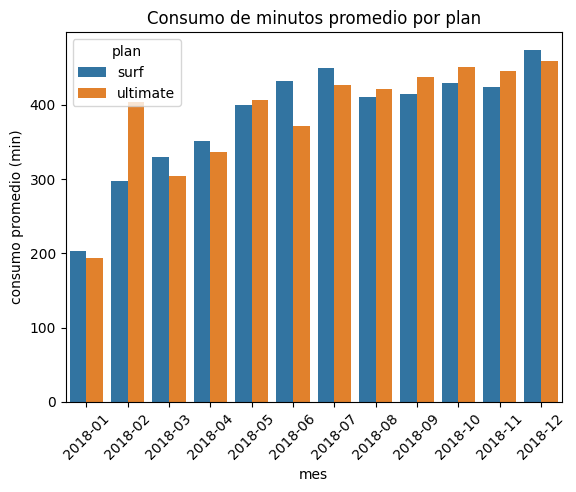

In [31]:
# Compara la duración promedio de llamadas por cada plan y por cada mes. Traza un gráfico de barras para visualizarla.

# Agrupar por mes y plan para obtener promedios mensuales
df_monthly_avg_by_plan = df_user_monthly.groupby(['year_month', 'plan'])['minutes_used'].mean().reset_index()

#df_monthly_avg_plan = df_calls_clean.groupby(['year_month', 'plan'])['duration_round'].mean().reset_index()
print(df_monthly_avg_by_plan.head(10))

#Grágico de barras:

sns.barplot(data = df_monthly_avg_by_plan, x = 'year_month', y = 'minutes_used', hue = 'plan')
plt.title('Consumo de minutos promedio por plan')
plt.xlabel('mes')
plt.ylabel('consumo promedio (min)')
plt.xticks(rotation=45)
plt.show()

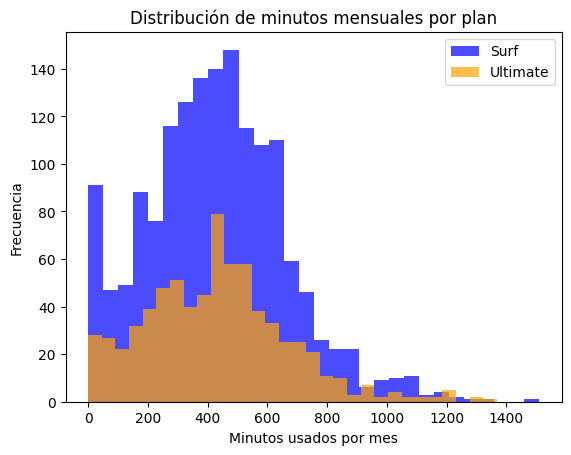

In [32]:
# Compara el número de minutos mensuales que necesitan los usuarios de cada plan. Traza un histograma.

surf_minutes = df_user_monthly[df_user_monthly['plan']== 'surf']['minutes_used']
ultimate_minutes = df_user_monthly[df_user_monthly['plan']== 'ultimate']['minutes_used']

plt.hist(surf_minutes, bins=30, alpha=0.7, label='Surf', color='blue')
plt.hist(ultimate_minutes, bins=30, alpha=0.7, label='Ultimate', color='orange')
plt.xlabel('Minutos usados por mes')
plt.ylabel('Frecuencia')
plt.title('Distribución de minutos mensuales por plan')
plt.legend()
plt.show()

In [33]:
# Calcula la media y la varianza de la duración mensual de llamadas.

call_stats_plan = df_user_monthly.groupby(['plan', 'year_month'])['minutes_used'].agg(['mean', 'var', 'std', 'count'])
print("Estadísticas de minutos mensuales por plan:")
print(call_stats_plan)


Estadísticas de minutos mensuales por plan:
                           mean           var         std  count
plan     year_month                                             
surf     2018-01     203.000000  15842.000000  125.865007      2
         2018-02     297.000000  52226.500000  228.531179      9
         2018-03     330.000000  35809.363636  189.233622     23
         2018-04     351.540000  50866.743265  225.536567     50
         2018-05     399.584416  59754.219754  244.446763     77
         2018-06     431.298969  45592.628436  213.524304     97
         2018-07     449.983471  61005.099725  246.992105    121
         2018-08     410.111111  54344.645963  233.119381    162
         2018-09     414.226804  46595.958656  215.860971    194
         2018-10     429.729958  52278.664056  228.645280    237
         2018-11     423.325088  51607.021602  227.171789    283
         2018-12     473.836478  63629.518918  252.248923    318
ultimate 2018-01     193.500000  16572.333333 

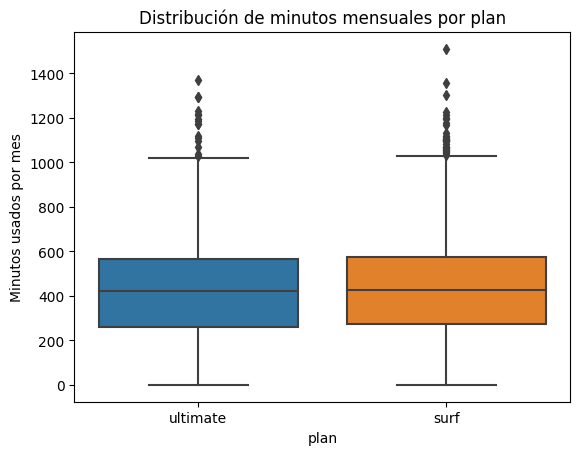

In [34]:
# Traza un diagrama de caja para visualizar la distribución de la duración mensual de llamadas

sns.boxplot(data=df_user_monthly, x='plan', y='minutes_used')
plt.title('Distribución de minutos mensuales por plan')
plt.ylabel('Minutos usados por mes')
plt.show()

De acuerdo con consumo mensual promedio de minutos se puede mencionar lo siguiente:
El plan “surf” experimentó un crecimiento en el consumo mensual superando los 400 minutos desde junio. Desde entonces este consumo se ha manejado con relativa estabilidad.
El plan “ultimate” presentó un comportamiento similar al plan “surf”, un crecimiento que se fue estancando en el mes de junio. Posiblemente se deba a que ambos planes fueron establecidos iniciando el año 2018. 
Los usuarios del plan “ultimate” consumen mucho menos minutos que los ofrecidos en el plan, lo que significa que están pagando por minutos que no consumen.
La distribución de consumo de minutos sigue una distribución normal para ambos planes. Para el plan “surf” se observa incluso un valor atipico de consumos de 0 minutos para cerca de 90 usuarios, lo que puede deberse a desconocimiento del plan adquirido. 
El plan “surf” tiene un mayor alcance que el plan “ultimate” que obedece al bajo precio que se debe pagar. Sin embargo, también se observa que los usuarios de este plan suelen consumir muchos mas minutos que los ofrecidos en el plan.
Se observa una alta dispersión de los consumos para ambos planes. Sin embargo las medianas y los cuartiles son muy similares, solo variando en los consumos máximos.
Para revisar: la posibilidad de reducir los minutos ofrecidos en el plan “ultimate” a máximo 1500-2000 minutos.
Aumentar el consumo de minutos para los usuarios del plan “surf” o incluso reducir un poco el valor del minuto adicional. 


### Mensajes

  year_month      plan  messages_sent
0    2018-01      surf      10.500000
1    2018-01  ultimate      15.500000
2    2018-02      surf      12.000000
3    2018-02  ultimate      21.571429
4    2018-03      surf      15.260870
5    2018-03  ultimate      20.250000
6    2018-04      surf      17.400000
7    2018-04  ultimate      22.047619
8    2018-05      surf      24.012987
9    2018-05  ultimate      32.103448


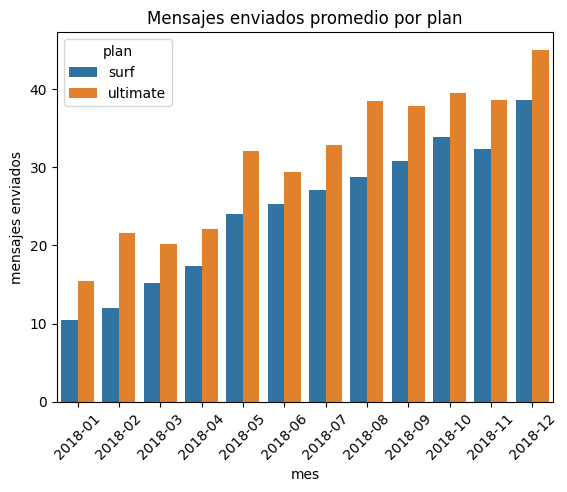

In [35]:
# Comprara el número de mensajes que tienden a enviar cada mes los usuarios de cada plan

# Agrupar por mes y plan para obtener promedios mensuales
df_monthly_avg_message_plan = df_user_monthly.groupby(['year_month', 'plan'])['messages_sent'].mean().reset_index()

print(df_monthly_avg_message_plan.head(10))

#Grágico de barras:

sns.barplot(data = df_monthly_avg_message_plan, x = 'year_month', y = 'messages_sent', hue = 'plan')
plt.title('Mensajes enviados promedio por plan')
plt.xlabel('mes')
plt.ylabel('mensajes enviados')
plt.xticks(rotation=45)
plt.show()

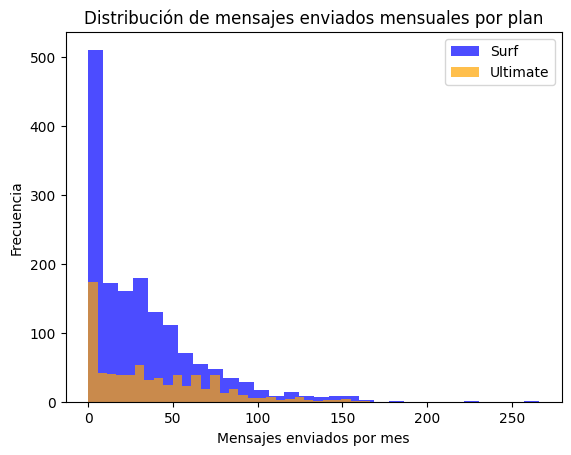

In [36]:
# Compara el número de mensajes mensuales que necesitan los usuarios de cada plan. Traza un histograma.

surf_messages = df_user_monthly[df_user_monthly['plan']== 'surf']['messages_sent']
ultimate_messages = df_user_monthly[df_user_monthly['plan']== 'ultimate']['messages_sent']

plt.hist(surf_messages, bins=30, alpha=0.7, label='Surf', color='blue')
plt.hist(ultimate_messages, bins=30, alpha=0.7, label='Ultimate', color='orange')
plt.xlabel('Mensajes enviados por mes')
plt.ylabel('Frecuencia')
plt.title('Distribución de mensajes enviados mensuales por plan')
plt.legend()
plt.show()


Estadísticas de mensages mensuales por plan:
                          mean          var        std  count
plan     year_month                                          
surf     2018-01     10.500000   220.500000  14.849242      2
         2018-02     12.000000   386.000000  19.646883      9
         2018-03     15.260870   346.565217  18.616262     23
         2018-04     17.400000   501.591837  22.396246     50
         2018-05     24.012987   847.197198  29.106652     77
         2018-06     25.298969   914.920103  30.247646     97
         2018-07     27.033058   923.915565  30.395979    121
         2018-08     28.777778  1029.515528  32.086064    162
         2018-09     30.762887  1003.829496  31.683268    194
         2018-10     33.839662  1275.465708  35.713663    237
         2018-11     32.385159  1065.344034  32.639608    283
         2018-12     38.600629  1458.158612  38.185843    318
ultimate 2018-01     15.500000   313.666667  17.710637      4
         2018-02     21.5

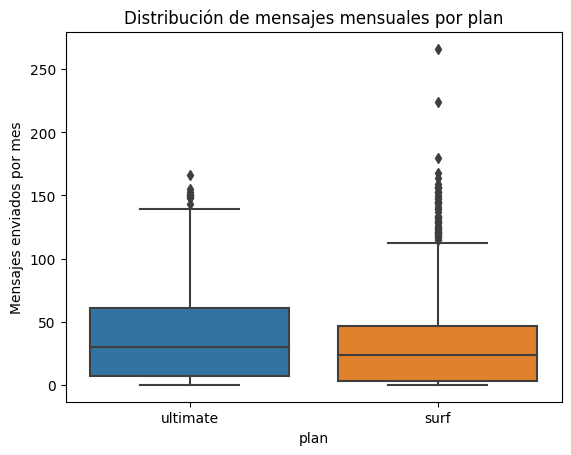

In [37]:
# Calcula la media y la varianza de los mensages enviados mensualmente.

messages_stats_plan = df_user_monthly.groupby(['plan', 'year_month'])['messages_sent'].agg(['mean', 'var', 'std', 'count'])
print("Estadísticas de mensages mensuales por plan:")
print(messages_stats_plan)

# Diagrama de caja para visualizar la distribución de los mensages enviados

sns.boxplot(data=df_user_monthly, x='plan', y='messages_sent')
plt.title('Distribución de mensajes mensuales por plan')
plt.ylabel('Mensajes enviados por mes')
plt.show()

Para el consumo mensual de mensajes se observa:
Un comportamiento similar de mensajes enviados en ambos planes. Los usuarios del plan “ultimate” en general suelen enviar más mensajes posiblemente debido a la cobertura de mensajes que tienen. no obstante, en casos aislados, se observa que hay algunos usuarios del plan "surf" que pueden llegar a enviar hasta mas de 4 veces los mensajes incluidos en el plan.
El crecimiento en el envío de mensajes para ambos planes es similar. Sin embargo en promedio los usuarios de ambos planes envían menos mensajes que el valor máximo ofrecido en el plan.
Los usuarios del plan “ultimate” envían un 90% menos mensajes que los incluidos dentro del plan. Al igual que con las llamadas, están pagando por mensajes que no se envían.
La distribución de envío de mensajes sigue un comportamiento decreciente. Incluso se observa que hay usuarios en ambos planes que no suelen enviar mensajes, posiblemente debido a que viene incluido un plan de internet y no requieren el envío de mensajes.
Se observa una mayor presencia de usuarios en el plan "surf" debido al bajo precio del plan.
De acuerdo con el diagrama de caja, los usuarios de ambos planes hacen uso de los mensajes que vienen dentro del plan. 
Al igual que en el caso de las llamadas, se observa una amplia dispersión de datos para ambos planes. 
Para revisar: la posibilidad de reducir drásticamente los mensajes ofrecidos en el plan  “ultimate” a máximo 300 mensajes.
No sería necesario aumentar la oferta de mensajes para los usuarios del plan “surf” pero si se puede evaluar la opción de reducir el costo por mensaje adicional. 


### Internet

  year_month      plan    gb_used
0    2018-01      surf   5.000000
1    2018-01  ultimate   7.250000
2    2018-02      surf  12.222222
3    2018-02  ultimate  17.285714
4    2018-03      surf  13.565217
5    2018-03  ultimate  18.416667
6    2018-04      surf  12.220000
7    2018-04  ultimate  16.333333
8    2018-05      surf  14.116883
9    2018-05  ultimate  16.862069


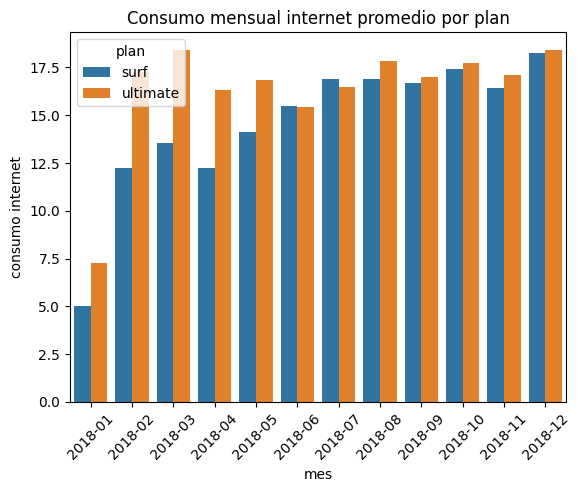

In [38]:
# Compara la cantidad de tráfico de Internet consumido por usuarios por plan

# Agrupar por mes y plan para obtener promedios mensuales
df_monthly_avg_internet_plan = df_user_monthly.groupby(['year_month', 'plan'])['gb_used'].mean().reset_index()

print(df_monthly_avg_internet_plan.head(10))

#Grágico de barras:

sns.barplot(data = df_monthly_avg_internet_plan, x = 'year_month', y = 'gb_used', hue = 'plan')
plt.title('Consumo mensual internet promedio por plan')
plt.xlabel('mes')
plt.ylabel('consumo internet')
plt.xticks(rotation=45)
plt.show()

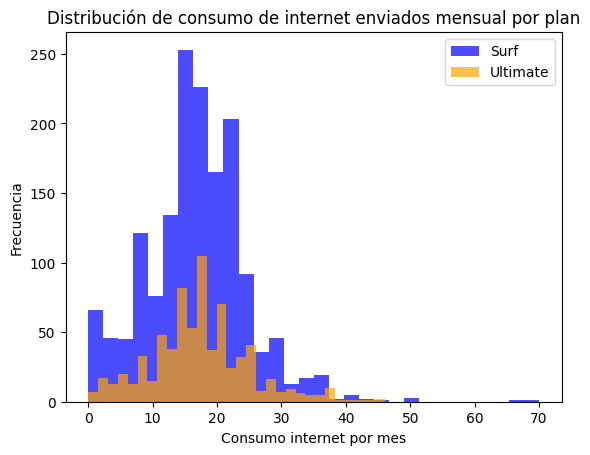

In [39]:
# Compara el consumo mensual de internet que necesitan los usuarios de cada plan. Traza un histograma.

surf_internet = df_user_monthly[df_user_monthly['plan']== 'surf']['gb_used']
ultimate_internet = df_user_monthly[df_user_monthly['plan']== 'ultimate']['gb_used']

plt.hist(surf_internet, bins=30, alpha=0.7, label='Surf', color='blue')
plt.hist(ultimate_internet, bins=30, alpha=0.7, label='Ultimate', color='orange')
plt.xlabel('Consumo internet por mes')
plt.ylabel('Frecuencia')
plt.title('Distribución de consumo de internet enviados mensual por plan')
plt.legend()
plt.show()

Estadísticas de consumo de internet mensual por plan:
                          mean         var        std  count
plan     year_month                                         
surf     2018-01      5.000000   18.000000   4.242641      2
         2018-02     12.222222   41.444444   6.437736      9
         2018-03     13.565217   63.984190   7.999012     23
         2018-04     12.220000   56.215918   7.497728     50
         2018-05     14.116883   58.183527   7.627813     77
         2018-06     15.484536   47.752363   6.910308     97
         2018-07     16.876033   61.476171   7.840674    121
         2018-08     16.882716   71.420942   8.451091    162
         2018-09     16.690722   49.240639   7.017167    194
         2018-10     17.409283   60.725846   7.792679    237
         2018-11     16.431095   54.607824   7.389711    283
         2018-12     18.238994   69.210841   8.319305    318
ultimate 2018-01      7.250000   14.916667   3.862210      4
         2018-02     17.285714 

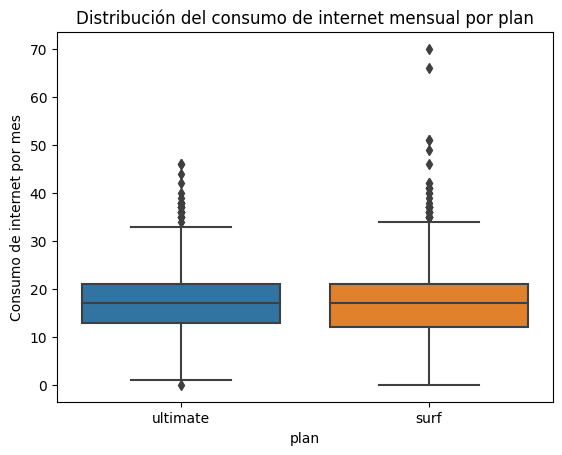

In [40]:
# Calcula la media y la varianza del consumo mensual de internet.

internet_stats_plan = df_user_monthly.groupby(['plan', 'year_month'])['gb_used'].agg(['mean', 'var', 'std', 'count'])
print("Estadísticas de consumo de internet mensual por plan:")
print(internet_stats_plan)

# Diagrama de caja para visualizar la distribución del consumo de internet

sns.boxplot(data=df_user_monthly, x='plan', y='gb_used')
plt.title('Distribución del consumo de internet mensual por plan')
plt.ylabel('Consumo de internet por mes')
plt.show()

Para el consumo de internet se puede mencionar:
Los consumos promedio mensual muestran un incremento drástico entre enero y febrero. Luego los consumos en promedio tienden a estabilizarse en valores entre los 12 y los 15 Gb.
Los usuarios del plan “surf” suelen exceder el consumo máximo ofrecido en el plan hasta un 10%.
En promedio los usuarios del plan “ultimate” consumen un 40% menos Gb que los ofrecidos en el plan.
Se observa un mayor numero de usuarios que consumen internet en el plan “surf” indudablemente por el precio que deben pagar y también un buen número de usuarios de este plan que exceden el consumo mensual incluido, ocasionando un ingreso adicional.
La distribución de consumo de internet sigue el comportamiento de distribución normal con un pequeño sesgo a la derecha.
Algo que se debe mencionar es que los usuarios del plan “ultimate” pueden llegar a consumir el máximo de Gb ofrecidos en el plan con algunos usuarios que consumen Gb adicionales.
Para el plan “surf” los consumos son muy similares al plan “ultimate” generando un sobrecosto. Incluso hay usuarios que consumen hasta 70Gb de internet.
La dispersión del consumo de internet es alta pero en un valor menor a lo observado con las llamadas y mensajes. 
Para revisar: Se podría considerar un lígero aumento en la oferta de Gb ofrecido al para ambos planes. Tal vez 40Gb para el plan “ultimate” y 20 Gb para el plan “surf” 



## Ingreso

  year_month      plan  monthly_revenue
0    2018-01      surf        20.000000
1    2018-01  ultimate        70.000000
2    2018-02      surf        34.396667
3    2018-02  ultimate        70.000000
4    2018-03      surf        45.941304
5    2018-03  ultimate        74.666667
6    2018-04      surf        40.710600
7    2018-04  ultimate        73.000000
8    2018-05      surf        47.628182
9    2018-05  ultimate        70.724138


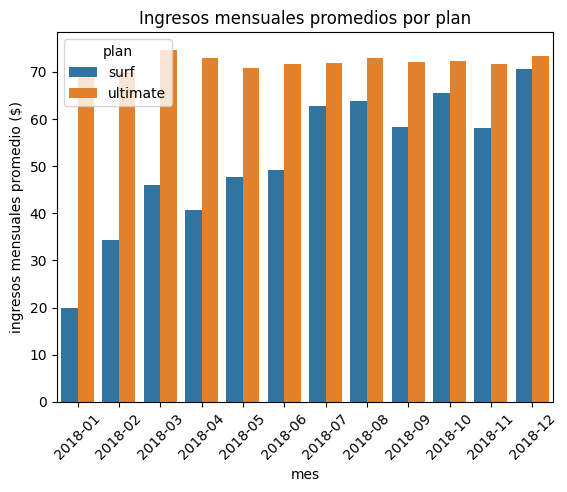

In [41]:
# Compara los ingresos mensuales por plan

# Agrupar por mes y plan para obtener promedios mensuales
df_monthly_avg_revenue = df_user_monthly.groupby(['year_month', 'plan'])['monthly_revenue'].mean().reset_index()

print(df_monthly_avg_revenue.head(10))

#Grágico de barras:

sns.barplot(data = df_monthly_avg_revenue, x = 'year_month', y = 'monthly_revenue', hue = 'plan')
plt.title('Ingresos mensuales promedios por plan')
plt.xlabel('mes')
plt.ylabel('ingresos mensuales promedio ($)')
plt.xticks(rotation=45)
plt.show()

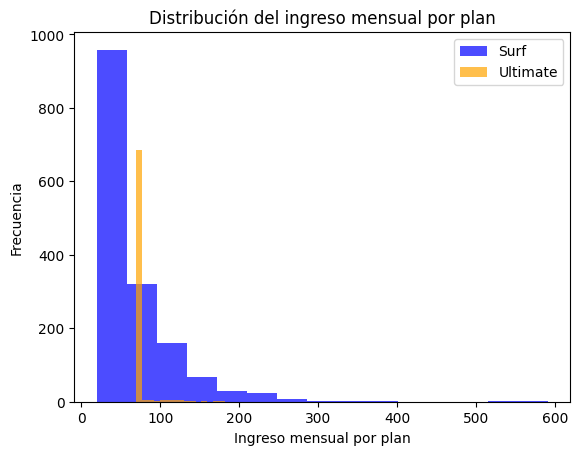

In [42]:
# Compara el ingreso mensual de cada plan. Traza un histograma.

surf_revenue = df_user_monthly[df_user_monthly['plan']== 'surf']['monthly_revenue']
ultimate_revenue = df_user_monthly[df_user_monthly['plan']== 'ultimate']['monthly_revenue']

plt.hist(surf_revenue, bins=15, alpha=0.7, label='Surf', color='blue')
plt.hist(ultimate_revenue, bins=15, alpha=0.7, label='Ultimate', color='orange')
plt.xlabel('Ingreso mensual por plan')
plt.ylabel('Frecuencia')
plt.title('Distribución del ingreso mensual por plan')
plt.legend()
plt.show()

Ingresos mensuales por plan:
                          mean          var        std  count
plan     year_month                                          
surf     2018-01     20.000000     0.000000   0.000000      2
         2018-02     34.396667   428.276100  20.694833      9
         2018-03     45.941304  1512.023512  38.884747     23
         2018-04     40.710600  1198.958402  34.625979     50
         2018-05     47.628182  1967.540055  44.356962     77
         2018-06     49.276289  1988.914046  44.597243     97
         2018-07     62.674050  2943.388409  54.253004    121
         2018-08     63.931173  3587.494901  59.895700    162
         2018-09     58.271495  2260.644980  47.546240    194
         2018-10     65.421224  3198.242612  56.553007    237
         2018-11     58.004276  2494.182230  49.941788    283
         2018-12     70.557044  4604.410868  67.855809    318
ultimate 2018-01     70.000000     0.000000   0.000000      4
         2018-02     70.000000     0.0000

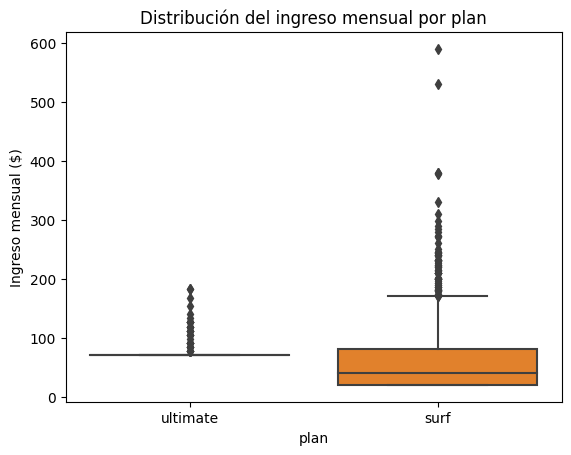

In [43]:
# Calcula la media y la varianza del ingreso mensual.

revenue_stats_plan = df_user_monthly.groupby(['plan', 'year_month'])['monthly_revenue'].agg(['mean', 'var', 'std', 'count'])
print("Ingresos mensuales por plan:")
print(revenue_stats_plan)

# Diagrama de caja para visualizar la distribución del ingreso mensual

sns.boxplot(data=df_user_monthly, x='plan', y='monthly_revenue')
plt.title('Distribución del ingreso mensual por plan')
plt.ylabel('Ingreso mensual ($)')
plt.show()

Los ingresos por plan a nivel mensual muestran lo siguiente:

En promedio, los usuarios del plan “ultimate” no generan un mayor ingreso adicional. Esto se debe a que consumen mucho menos minutos y mensajes que los incluidos en el plan. El lígero aumento de ingresos es debido únicamente al consumo de internet.

En promedio, los usuarios del plan “surf” muestran un aumento de los pagos realizados. Debido a los minutos, mensajes e internet adicional consumido. Incluso en diciembre de 2018 en promedio pagaron lo mismo que para el plan “ultimate”.

La distribución de ingresos para el plan “surf” es decreciente. Y se observa que hay un buen número de usuarios, mayor a 100, que pagan hasta %100 o mas por consumos.

La dispersión de datos para el plan “surf” es muy alta, y para el plan “ultimate” es pequeña, eso debido a que no hay un ingreso mucho mayor.

Hay algunos usuarios del plan “ultimate” que pagan hasta $200 mensuales por su consumo. Para el plan “surf” este ingreso puede ser hasta de $600.

En general los usuarios del plan “surf” pagan mucho más de lo que pagan por su plan original, debido al sobreconsumo de minutos, mensajes e internet. 

Para revisar: dado a que en diciembre se observó que en promedio los usuarios del plan “surf” pagaron mas de $70 por consumo mensual se podría:

1.	Eliminar el plan “surf” y ajustar el plan “ultimate” a menos llamadas y mensajes, aumentando el consumo de internet a 40 Gb.
2.	Realizar una revisión individualizada de consumos y ofrecerle a los clientes que presentan un mayor consumo un cambio de plan que se ajuste a sus consumos.


## Prueba las hipótesis estadísticas

H0: No hay diferencias en los ingresos promedio de los usuarios de planes ultimate y surf.

H1: Hay diferencia en el ingreso promedio de los planes.

Alpha: 0.01

Los ingresos promedio no guardan una distribución normal, por lo cual se debe realizar una prueba sobre igualdad de las medias, con una incertidumbre del 1%

In [44]:
# Prueba las hipótesis

# Separar los ingresos por plan
surf_revenue = df_user_monthly[df_user_monthly['plan'] == 'surf']['monthly_revenue']
ultimate_revenue = df_user_monthly[df_user_monthly['plan'] == 'ultimate']['monthly_revenue']

# Realizar prueba t para muestras independientes
alpha = 0.01  # Nivel de significancia más estricto
results = st.ttest_ind(surf_revenue, ultimate_revenue, equal_var=False)

print(f'Valor p: {results.pvalue}')
if results.pvalue < alpha:
    print("Rechazamos la hipótesis nula")
else:
    print("No podemos rechazar la hipótesis nula")

# Calcula las medias para interpretar la dirección de la diferencia
print(f"Ingreso promedio plan Surf: ${surf_revenue.mean():.2f}")
print(f"Ingreso promedio plan Ultimate: ${ultimate_revenue.mean():.2f}")

Valor p: 3.1703905481135734e-15
Rechazamos la hipótesis nula
Ingreso promedio plan Surf: $60.71
Ingreso promedio plan Ultimate: $72.31


H0: no hay diferencia en el ingreso promedio de los usuarios del área de NY-NJ y los usuarios de otras regiones

H1: Hay diferencias en el ingreso promedio de los usuarios del área de NY-NJ y los usuarios de otras regiones.

Alpha: 0.01

Los ingresos promedio no guardan una distribución normal, por lo cual se debe realizar una prueba sobre igualdad de las medias, con una incertidumbre del 1%

Estadísticas de ingresos por región:
            mean  median        std  count
ny_nj                                     
False  64.231506   70.00  46.480469   2264
True   73.691379   62.37  56.984031     29

Tamaño muestra NY-NJ: 29
Tamaño muestra otras regiones: 2264


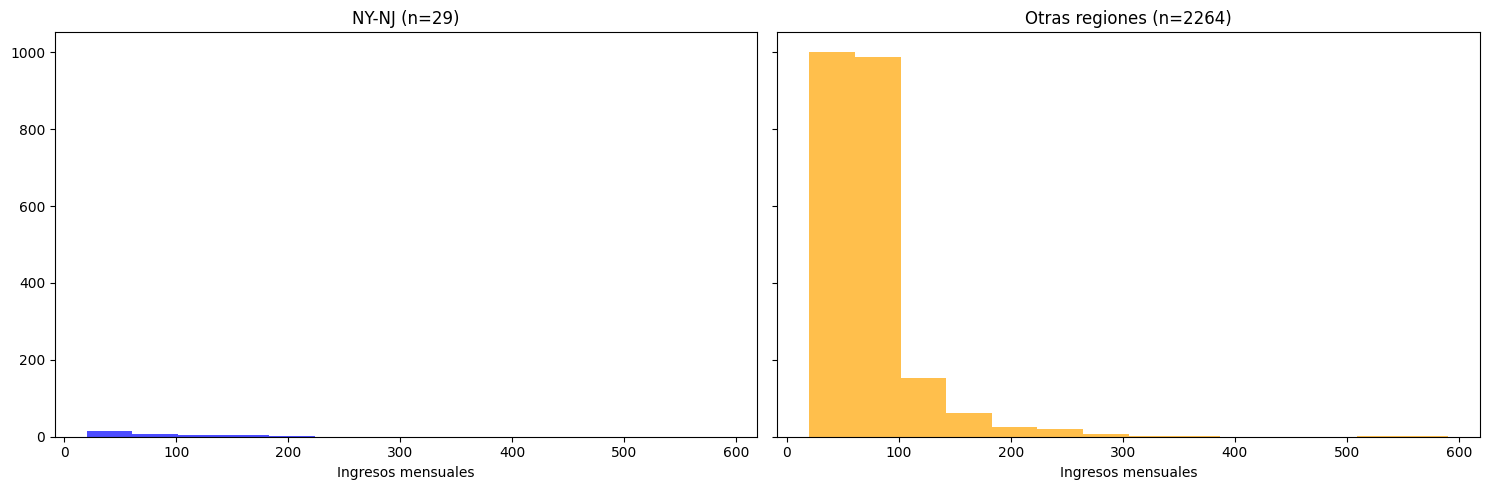

Valor p: 0.3808163441228868
No podemos rechazar la hipótesis nula
No hay evidencia suficiente de diferencia entre regiones
Ingreso promedio NY-NJ: $73.69
Ingreso promedio otras regiones: $64.23


In [45]:
# Prueba las hipótesis

# Usuarios de NY-NJ del dataframe df_users_clean
df_users_clean['ny_nj'] = df_users_clean['state'].isin(['NY', 'NJ'])

# Agregar la información a df_user_monthly
df_user_monthly_region = df_user_monthly.merge(df_users_clean[['user_id', 'ny_nj']], on='user_id')

# Estadísticas descriptivas por región
regional_stats = df_user_monthly_region.groupby('ny_nj')['monthly_revenue'].agg(['mean', 'median', 'std', 'count'])
print("Estadísticas de ingresos por región:")
print(regional_stats)
print()

# Segmentar los ingresos mensuales por región
ny_nj_revenue = df_user_monthly_region[df_user_monthly_region['ny_nj'] == True]['monthly_revenue']
other_revenue = df_user_monthly_region[df_user_monthly_region['ny_nj'] == False]['monthly_revenue']

print(f"Tamaño muestra NY-NJ: {len(ny_nj_revenue)}")
print(f"Tamaño muestra otras regiones: {len(other_revenue)}")

# Verificar normalidad visualmente
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Definir los valores mínimo y máximo para los bins
min_val = df_user_monthly_region['monthly_revenue'].min()
max_val = df_user_monthly_region['monthly_revenue'].max()

# Usar los mismos bins para ambos gráficos
bins = np.linspace(min_val, max_val, 15)

ax1.hist(ny_nj_revenue, bins=bins, alpha=0.7, color='blue')
ax1.set_title(f'NY-NJ (n={len(ny_nj_revenue)})')
ax1.set_xlabel('Ingresos mensuales')

ax2.hist(other_revenue, bins=bins, alpha=0.7, color='orange')
ax2.set_title(f'Otras regiones (n={len(other_revenue)})')
ax2.set_xlabel('Ingresos mensuales')

plt.tight_layout()
plt.show()

# Realizar prueba t para muestras independientes
alpha = 0.01  # Mismo nivel de significancia
results = st.ttest_ind(ny_nj_revenue, other_revenue, equal_var=False)

print(f'Valor p: {results.pvalue}')
if results.pvalue < alpha:
    print("Rechazamos la hipótesis nula")
    print("Existe diferencia significativa entre las regiones")
else:
    print("No podemos rechazar la hipótesis nula")
    print("No hay evidencia suficiente de diferencia entre regiones")

# Mostrar las medias para interpretar la dirección
print(f"Ingreso promedio NY-NJ: ${ny_nj_revenue.mean():.2f}")
print(f"Ingreso promedio otras regiones: ${other_revenue.mean():.2f}")

## Conclusión general

Se ha realizado un análisis de los datos de consumo de 500 usuarios de la compañía telefónica Megaline en 2018.
Se realizó una revisión inicial y ajuste de los datos para un mejor manejo de los mismos y tener un análisis más sólido.

Se realizó un análisis de consumo mensual de minutos, mensajes y uso de internet para ambos planes ofrecidos, se identificó un patrón de sobreconsumo en el plan "surf" y un hipoconsumo en el plan "ultimate".

Se observa que hay una diferencia apreciable de consumo para los usuarios de ambos planes. Si bien, los usuarios del plan "surf" generan un ingreso menor que los usuarios del plan "ultimate" cerca de $10, los usuarios del plan "surf" generan un ingreso mayor debido al consumo de minutos, mensajes y consumo de internet superior a lo incluido dentro del plan.

Podría evaluarse un análisis mas personalizado para ofrecerle al cliente un ligero incremento en su plan para tener mas minutos e internet.

Para el caso de la segmentación por regiones ocurre una situación particular. La diferencia de ingresos promedio mensual es muy similar a la diferencia de ingresos por planes, cercana a los $10, sin embargo, se debe tener en cuenta que la desviación estándar de ambas regiones es muy alta, y adicionalmente, se cuenta con una muestra de solo 29 usuarios de la zona de NY-NJ, lo cual impide generar una conclusión definitiva sobre los ingresos promedio por regiones.

Como recomendaciones finales se tienen:

1. Evaluar para el plan "surf" una mejora, ya sea en la cantidad incluida de minutos e internet o reducir los valores de minutos e internet adicionales. Esto debe ir acompañado de un estudio de rentabilidad.
2. para el plan "ultimate" puede revisase la reducción de minutos y mensajes incluidos. Este es un plan premium que se puede sostener.
